# TP 7 — Régression logistique et bilan : le Titanic

---
##  Contexte et objectif du TP
C'est le **TP de synthèse** du module. On prédit la **survie des passagers du Titanic** (891 passagers, cible `Survived` : 1 = a survécu)
avec une **régression logistique**, puis on **compare tous les algorithmes** vus dans les TP précédents.

Malgré son nom, la régression logistique est un modèle de **classification** : elle calcule un **score** (comme une régression
linéaire), puis le transforme en **probabilité** grâce à la **sigmoïde**. Simple et **explicable**, c'est le modèle de référence
en médecine et en banque, là où il faut **justifier chaque décision**.

Ce TP a pour but de :
1. comprendre comment un **score** devient une **probabilité** (la sigmoïde) ;
2. **lire un coefficient** grâce au **rapport de cotes** (*odds ratio*) ;
3. étudier l'effet du **seuil** de décision sur la matrice de confusion et la **courbe ROC** ;
4. **comparer** régression logistique, arbre de décision, KNN et forêt aléatoire, avec le critère de l'**explicabilité** ;
5. refaire la comparaison dans **Orange**.

| Partie | Contenu | Points |
|---|---|---|
| **A** | Préparer les données | 2 |
| **B** | Régression logistique avec Python | 11 |
| **C** | Bilan : comparer tous les modèles | 4 |
| **D** | Avec Orange | 3 |

##  Rappel : régression logistique
* **Score** : z = b₀ + b₁x₁ + … + bₚxₚ (comme une régression linéaire) ;
* **Probabilité** : P(y = 1) = σ(z) = 1 / (1 + e⁻ᶻ), **toujours entre 0 et 1** ;
* **Rapport de cotes** : e^(bⱼ). La **cote** P/(1 − P) est **multipliée par e^(bⱼ)** quand xⱼ augmente de 1.

##  Livrables
Ce notebook exécuté (`.ipynb`), le fichier Orange (`.ows`) et le **tableau comparatif des modèles** (produit en partie C, aussi enregistré en CSV).

## 📖 Mini-glossaire
| Terme | Signification | Pourquoi on en a besoin |
|---|---|---|
| **Importation** | Charger bibliothèques et fichier | Point de départ |
| **Exploration / Visualisation** | Résumer et tracer les données | Comprendre avant de modéliser |
| **Imputation** | Remplacer les valeurs manquantes (médiane pour l'âge, modalité la plus fréquente pour le port) | Les modèles n'acceptent pas les cases vides |
| **Création de variables** | `femme` (0/1), `famille` = SibSp + Parch | Rendre l'information exploitable par le modèle |
| **Séparation train/test (75/25, stratifiée)** | Apprendre sur 75 %, évaluer sur 25 % en gardant la même proportion de survivants | Évaluer sur des passagers jamais vus |
| **Sigmoïde** | Fonction qui transforme n'importe quel score en nombre entre 0 et 1 | Obtenir une **probabilité** |
| **Rapport de cotes (odds ratio)** | e^coefficient : facteur multiplicatif de la cote de survie | Interpréter chaque variable |
| **Pipeline** | Enchaînement prétraitement + modèle | Éviter les fuites d'information et rejouer la même préparation |
| **Seuil de décision** | Probabilité à partir de laquelle on prédit « a survécu » (0,5 par défaut) | Arbitrer entre types d'erreurs |
| **Précision / Rappel** | Parmi les « survivants » prédits, part de vrais / parmi les vrais survivants, part retrouvée | Mesurer deux façons différentes de se tromper |
| **Courbe ROC / AUC** | Taux de vrais positifs selon le taux de faux positifs pour tous les seuils / aire sous la courbe (1 = parfait, 0,5 = hasard) | Évaluer un modèle indépendamment du seuil |
| **Validation croisée** | 10 découpages du train, test à chaque fois sur un pli différent | Comparer les modèles de façon fiable, sans toucher au test |
| **Explicabilité** | Capacité à justifier une décision | Critère de choix aussi important que le score |

## 0. Importation des bibliothèques et du fichier

**Importation** : `numpy`/`pandas`, `matplotlib`, et `scikit-learn` : les quatre modèles comparés
(`LogisticRegression`, `DecisionTreeClassifier`, `KNeighborsClassifier`, `RandomForestClassifier`),
les outils de prétraitement (`Pipeline`, `ColumnTransformer`, `StandardScaler`, `OneHotEncoder`, `FunctionTransformer`)
et les métriques (accuracy, matrice de confusion, ROC, AUC, précision, rappel).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_score, recall_score)

pd.set_option("display.max_columns", 30)
print("Bibliothèques importées ✅")

Bibliothèques importées ✅


**Importation du fichier** : sur Colab, il faut envoyer `titanic.csv` depuis votre ordinateur
(en Jupyter local, placez-le dans le même dossier que le notebook).

---
# PARTIE A — Préparer · *2 points*
**But** : transformer les données brutes en variables utilisables par un modèle, puis séparer train et test.

## A.1 — Variables
### Importation et exploration
*Pourquoi ?* Repérer les colonnes utiles, les valeurs manquantes et le taux de survie global.

Dimensions : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Valeurs manquantes :
Age         177
Cabin       687
Embarked      2
dtype: int64

Taux de survie global : 0.384


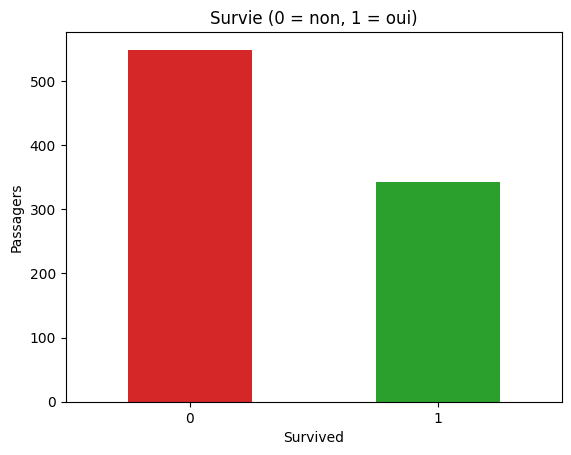

In [2]:
titanic = pd.read_csv("titanic.csv")                    # importation
print("Dimensions :", titanic.shape)
display(titanic.head())
print("\nValeurs manquantes :")
print(titanic.isna().sum()[titanic.isna().sum() > 0])

CIBLE = "Survived"
print(f"\nTaux de survie global : {titanic[CIBLE].mean():.3f}")
titanic[CIBLE].value_counts().sort_index().plot(kind="bar", rot=0, color=["tab:red", "tab:green"])
plt.title("Survie (0 = non, 1 = oui)"); plt.ylabel("Passagers"); plt.show()

### Création des variables et imputation
* **`femme`** : 1 si la passagère est une femme, 0 sinon (un modèle ne lit que des nombres) ;
* **`famille`** = `SibSp` + `Parch` (nombre de proches à bord : frères/sœurs/conjoint + parents/enfants) ;
* **`Age`** : valeurs manquantes remplacées par la **médiane** (robuste aux âges extrêmes) ;
* **`Embarked`** (port d'embarquement) : valeurs manquantes remplacées par la **modalité la plus fréquente**.

> Remarque : on impute ici avant de séparer, comme le demande l'énoncé. En pratique rigoureuse, on calculerait médiane et
> mode sur le **train seul** pour ne rien laisser « fuir » du test.

In [3]:
df = titanic.copy()

df["femme"] = df["Sex"].astype(str).str.lower().isin(["female", "femme", "f"]).astype(int)   # ⚠️ vérifier les valeurs de Sex
df["famille"] = df["SibSp"] + df["Parch"]

mediane_age = df["Age"].median()
df["Age"] = df["Age"].fillna(mediane_age)
mode_port = df["Embarked"].mode()[0]
df["Embarked"] = df["Embarked"].fillna(mode_port)
if df["Fare"].isna().any():
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

print(f"Âge médian utilisé : {mediane_age} | port le plus fréquent : {mode_port}")
print("Valeurs manquantes restantes dans les variables utiles :",
      int(df[["femme", "Age", "famille", "Fare", "Pclass", "Embarked"]].isna().sum().sum()))
print("Répartition femme :", df["femme"].value_counts().to_dict())

Âge médian utilisé : 28.0 | port le plus fréquent : S
Valeurs manquantes restantes dans les variables utiles : 0
Répartition femme : {0: 577, 1: 314}


### Séparation train / test (75 % / 25 %, stratifiée)
`stratify=y` garde la **même proportion de survivants** dans les deux jeux ; `random_state=42` rend la découpe reproductible.

In [4]:
FEATURES = ["femme", "Age", "famille", "Fare", "Pclass", "Embarked"]
X = df[FEATURES]
y = df[CIBLE]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print(f"Taux de survie  train : {y_train.mean():.3f} | test : {y_test.mean():.3f}")

Train : (668, 6) | Test : (223, 6)
Taux de survie  train : 0.383 | test : 0.386


✍️ **Ma réponse A.1** : valeurs manquantes trouvées = *(Age : …, Embarked : …, …)* ; âge médian = *(…)* ; port le plus fréquent = *(…)* ;
taux de survie global = *(…)* ; tailles train/test = *(…)*.

---
# PARTIE B — Régression logistique avec Python · *11 points*

## B.1 — Une seule variable : `femme`
**But** : voir la régression logistique dans sa version la plus simple, pour comprendre le lien **score → probabilité**.

Avec une seule variable binaire, le modèle n'a que deux scores possibles : z(homme) = b₀ et z(femme) = b₀ + b₁.
Chacun est transformé en probabilité par la **sigmoïde**. On compare ensuite aux **taux de survie observés** dans le train.

In [5]:
lr1 = LogisticRegression()                                     # régularisation L2 par défaut (C = 1)
lr1.fit(X_train[["femme"]], y_train)                           # ENTRAÎNEMENT

b0, b1 = lr1.intercept_[0], lr1.coef_[0][0]
p_homme = lr1.predict_proba(pd.DataFrame({"femme": [0]}))[0, 1]
p_femme = lr1.predict_proba(pd.DataFrame({"femme": [1]}))[0, 1]

obs = y_train.groupby(X_train["femme"]).mean()                  # taux de survie observés (train)

print(f"b0 = {b0:.3f} | b1 = {b1:.3f}")
print(f"Score homme = {b0:.3f}  -> P(survie) = {p_homme:.3f}   (taux observé : {obs[0]:.3f})")
print(f"Score femme = {b0 + b1:.3f}  -> P(survie) = {p_femme:.3f}   (taux observé : {obs[1]:.3f})")

# Même modèle quasiment sans régularisation (C très grand) : les probabilités collent exactement aux taux observés
lr1_libre = LogisticRegression(C=1e6).fit(X_train[["femme"]], y_train)
print("\nAvec C très grand (≈ pas de régularisation) :",
      lr1_libre.predict_proba(pd.DataFrame({"femme": [0, 1]}))[:, 1].round(3))

b0 = -1.449 | b1 = 2.503
Score homme = -1.449  -> P(survie) = 0.190   (taux observé : 0.184)
Score femme = 1.053  -> P(survie) = 0.741   (taux observé : 0.752)

Avec C très grand (≈ pas de régularisation) : [0.184 0.752]


**Visualisation : la sigmoïde.** Elle transforme tout score z (de −∞ à +∞) en probabilité entre 0 et 1.
Les deux points montrent les scores de l'homme et de la femme.

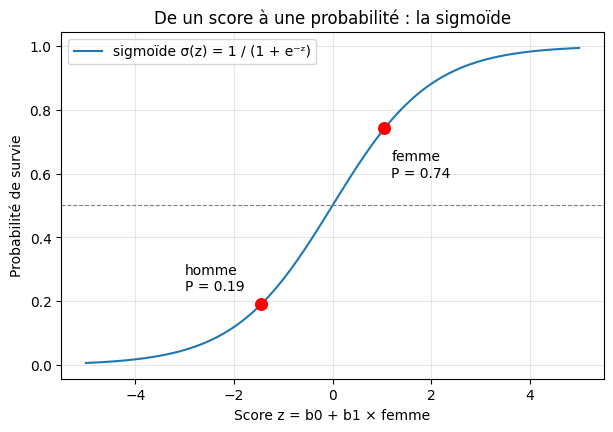

In [6]:
z = np.linspace(-5, 5, 200)
sigmoide = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4.5))
plt.plot(z, sigmoide, color="tab:blue", label="sigmoïde σ(z) = 1 / (1 + e⁻ᶻ)")
plt.scatter([b0, b0 + b1], [p_homme, p_femme], color="red", zorder=3, s=70)
plt.annotate(f"homme\nP = {p_homme:.2f}", (b0, p_homme), textcoords="offset points", xytext=(-55, 10))
plt.annotate(f"femme\nP = {p_femme:.2f}", (b0 + b1, p_femme), textcoords="offset points", xytext=(5, -35))
plt.axhline(0.5, color="gray", ls="--", lw=0.8)
plt.xlabel("Score z = b0 + b1 × femme"); plt.ylabel("Probabilité de survie")
plt.title("De un score à une probabilité : la sigmoïde")
plt.legend(); plt.grid(alpha=0.3); plt.show()

✍️ **Ma réponse B.1** : P(survie | homme) = *(…)*, P(survie | femme) = *(…)* ; taux observés dans le train = *(…)* et *(…)*.
Les valeurs sont *(très proches / légèrement différentes à cause de la régularisation par défaut ; avec C très grand elles sont identiques)*.
**Interprétation** : la sigmoïde « écrase » le score entre 0 et 1 ; un score positif donne une probabilité > 0,5.

## B.2 — Le modèle complet (Pipeline)
Un **Pipeline** enchaîne le prétraitement et le modèle : on l'entraîne sur le train, et le test subit **exactement les mêmes
transformations** (avec les paramètres appris sur le train). C'est la garantie de ne pas tricher.

Prétraitement :
* **`Age`, `famille`** → standardisés (moyenne 0, écart-type 1) ;
* **`Fare`** → `log1p` (log(1 + x)) puis standardisation : le prix du billet est très étalé (quelques billets très chers), le log « tasse » les valeurs extrêmes ;
* **`Pclass`, `Embarked`** → **one-hot** (une colonne 0/1 par modalité) ;
* **`femme`** → déjà 0/1, laissée telle quelle.

Accuracy test = 0.7713
AUC test      = 0.8387
Matrice de confusion [[VN, FP], [FN, VP]] :
 [[112  25]
 [ 26  60]]


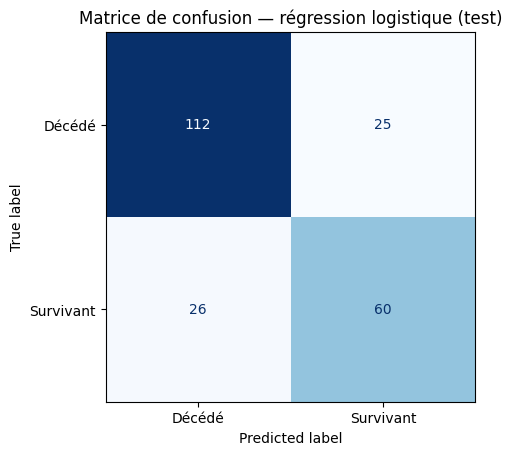

In [7]:
def faire_prepro(standardiser=True):
    """Construit le prétraitement ; standardiser=False sert plus tard à tester le KNN sans mise à l'échelle."""
    num = StandardScaler() if standardiser else "passthrough"
    fare = Pipeline([("log", FunctionTransformer(np.log1p)),
                     ("std", StandardScaler() if standardiser else "passthrough")])
    return ColumnTransformer([
        ("num", num, ["Age", "famille"]),
        ("fare", fare, ["Fare"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Pclass", "Embarked"]),
    ], remainder="passthrough")        # "femme" passe sans changement

pipe_log = Pipeline([("prepro", faire_prepro()), ("modele", LogisticRegression(max_iter=1000))])
pipe_log.fit(X_train, y_train)                                  # ENTRAÎNEMENT

proba_test = pipe_log.predict_proba(X_test)[:, 1]               # probabilité de survie
pred_test = (proba_test >= 0.5).astype(int)                     # décision au seuil 0,5

print(f"Accuracy test = {accuracy_score(y_test, pred_test):.4f}")
print(f"AUC test      = {roc_auc_score(y_test, proba_test):.4f}")

cm = confusion_matrix(y_test, pred_test)
print("Matrice de confusion [[VN, FP], [FN, VP]] :\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["Décédé", "Survivant"]).plot(cmap="Blues", colorbar=False)
plt.title("Matrice de confusion — régression logistique (test)"); plt.show()

✍️ **Ma réponse B.2** : accuracy = *(…)* ; AUC = *(…)* ; matrice de confusion : VN = *(…)*, FP = *(…)*, FN = *(…)*, VP = *(…)*.
Un AUC de *(…)* signifie que, pour un survivant et un non-survivant tirés au hasard, le modèle donne la plus forte probabilité au survivant dans *(…)* % des cas.

## B.3 — Lire les coefficients (rapport de cotes)
Cette fois, **on ne standardise pas** : les variables restent dans leurs unités (années, nombre de proches…), ce qui permet
d'interpréter chaque coefficient directement. La **classe** est mise en one-hot avec `drop_first=True` : la **1ʳᵉ classe devient la référence**.

Pour chaque variable, le **rapport de cotes = e^coefficient** : c'est le facteur par lequel la **cote de survie P/(1−P)**
est multipliée quand la variable augmente de 1 (toutes les autres restant égales).
* e^b > 1 : la variable **augmente** les chances de survie ; e^b < 1 : elle les **diminue**.

In [8]:
def variables_brutes(Xdf):
    """femme, Age, famille + classe en one-hot (1re classe = référence)."""
    out = Xdf[["femme", "Age", "famille"]].copy()
    classe = pd.get_dummies(Xdf["Pclass"].astype(int).astype(str), prefix="classe", dtype=float)
    return pd.concat([out, classe[["classe_2", "classe_3"]]], axis=1)

Xb_train = variables_brutes(X_train)
lr_brut = LogisticRegression(C=1e6, max_iter=5000)             # C très grand ≈ sans régularisation (lecture directe des coefficients)
lr_brut.fit(Xb_train, y_train)

tab = pd.DataFrame({"coefficient b": lr_brut.coef_[0],
                    "rapport de cotes e^b": np.exp(lr_brut.coef_[0])}, index=Xb_train.columns).round(3)
display(tab)

b = dict(zip(Xb_train.columns, lr_brut.coef_[0]))
print(f"👩 Être une femme : cote de survie multipliée par {np.exp(b['femme']):.1f}")
print(f"🎂 +10 ans d'âge  : cote multipliée par {np.exp(10 * b['Age']):.2f}  (= e^(10 × b_Age))")
print(f"🚢 3e plutôt que 1re classe : cote multipliée par {np.exp(b['classe_3']):.3f}")

,coefficient b,rapport de cotes e^b
femme,2.786,16.224
Age,-0.042,0.959
famille,-0.161,0.852
classe_2,-1.345,0.260
classe_3,-2.439,0.087


👩 Être une femme : cote de survie multipliée par 16.2
🎂 +10 ans d'âge  : cote multipliée par 0.66  (= e^(10 × b_Age))
🚢 3e plutôt que 1re classe : cote multipliée par 0.087


✍️ **Ma réponse B.3** :
* **Femme** : e^b = *(…)* → la cote de survie est multipliée par *(…)* par rapport à un homme (à âge, famille et classe égaux).
* **10 ans de plus** : e^(10·b_Age) = *(…)* → la cote est multipliée par *(…)* (donc *(−…) %*) : les passagers plus âgés survivent moins.
* **3e classe plutôt que 1re** : e^b = *(…)* → la cote est divisée par *(…)* : voyager en 3e classe réduit fortement les chances.
* ⚠️ Une **cote** n'est pas une **probabilité** : « cote × 2 » ne veut pas dire « probabilité × 2 ».

## B.4 — Rose et Jack
On utilise le **modèle de B.2** (Pipeline) pour prédire la probabilité de survie de deux passagers fictifs.
Il faut fournir **les mêmes colonnes** que celles utilisées à l'entraînement : `femme`, `Age`, `famille`, `Fare`, `Pclass`, `Embarked`.

* **Rose** : femme, 17 ans, 1ʳᵉ classe, 150 livres, Southampton (`S`), 1 parent (`famille` = 1) ;
* **Jack** : homme, 20 ans, 3ᵉ classe, 8 livres, Southampton (`S`), seul (`famille` = 0).

In [9]:
passagers = pd.DataFrame([
    {"femme": 1, "Age": 17, "famille": 1, "Fare": 150, "Pclass": 1, "Embarked": "S"},   # Rose
    {"femme": 0, "Age": 20, "famille": 0, "Fare": 8,   "Pclass": 3, "Embarked": "S"},   # Jack
], index=["Rose", "Jack"])[FEATURES]

passagers["P(survie)"] = pipe_log.predict_proba(passagers[FEATURES])[:, 1].round(3)
display(passagers)

for nom in passagers.index:
    print(f"{nom} : probabilité de survie = {passagers.loc[nom, 'P(survie)']:.1%}")

,femme,Age,famille,Fare,Pclass,Embarked,P(survie)
Rose,1,17,1,150,1,S,0.966
Jack,0,20,0,8,3,S,0.121


Rose : probabilité de survie = 96.6%
Jack : probabilité de survie = 12.1%


✍️ **Ma réponse B.4** : P(Rose) = *(…)*, P(Jack) = *(…)*. Le modèle est cohérent avec les rapports de cotes de B.3 :
*(être une femme, de 1ʳᵉ classe, jouent fortement en faveur de Rose ; être un homme en 3ᵉ classe défavorise Jack)*.
Précaution : une probabilité est une **estimation statistique** sur des passagers semblables, pas une certitude individuelle.

## B.5 — Seuil et courbe ROC
Le modèle produit une **probabilité** ; la décision « survivant / décédé » dépend du **seuil** (0,5 par défaut).
* Un seuil **bas** (0,3) : on prédit « survivant » plus facilement → on retrouve **plus** de vrais survivants (**rappel ↑**)
  mais on se trompe plus souvent en annonçant un survivant (**précision ↓**).
* La **courbe ROC** montre ce compromis pour **tous** les seuils possibles ; l'**AUC** résume la qualité globale.

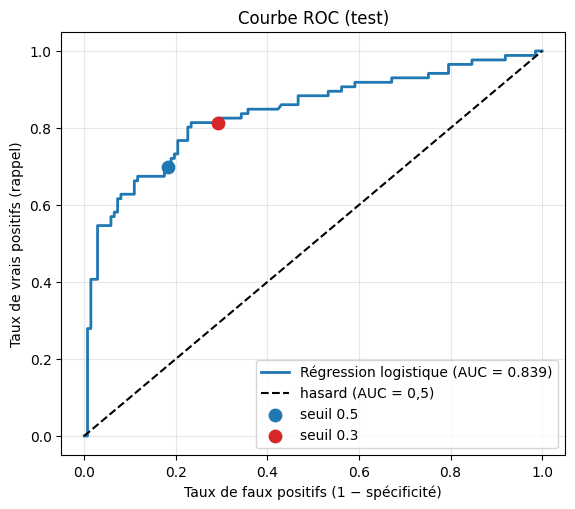

In [10]:
fpr, tpr, seuils = roc_curve(y_test, proba_test)
auc = roc_auc_score(y_test, proba_test)

def point_seuil(s):
    pred = proba_test >= s
    vp = (pred & (y_test == 1)).sum(); fp = (pred & (y_test == 0)).sum()
    return fp / (y_test == 0).sum(), vp / (y_test == 1).sum()

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr, tpr, lw=2, label=f"Régression logistique (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="hasard (AUC = 0,5)")
for s, c in ((0.5, "tab:blue"), (0.3, "tab:red")):
    fx, ty = point_seuil(s)
    plt.scatter(fx, ty, color=c, s=80, zorder=3, label=f"seuil {s}")
plt.xlabel("Taux de faux positifs (1 − spécificité)"); plt.ylabel("Taux de vrais positifs (rappel)")
plt.title("Courbe ROC (test)"); plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.show()

In [11]:
lignes = []
for s in (0.5, 0.3):
    pred = (proba_test >= s).astype(int)
    cm_s = confusion_matrix(y_test, pred)
    lignes.append({"seuil": s,
                   "rappel (survivants retrouvés)": round(recall_score(y_test, pred, pos_label=1), 3),
                   "précision (survivants annoncés justes)": round(precision_score(y_test, pred, pos_label=1), 3),
                   "accuracy": round(accuracy_score(y_test, pred), 3),
                   "FP": cm_s[0, 1], "FN": cm_s[1, 0]})
display(pd.DataFrame(lignes).set_index("seuil"))

,rappel (survivants retrouvés),précision (survivants annoncés justes),accuracy,FP,FN
seuil,,,,,
0.5,0.698,0.706,0.771,25,26
0.3,0.814,0.636,0.749,40,16


✍️ **Ma réponse B.5** : en passant de 0,5 à 0,3, le **rappel** de la classe « a survécu » passe de *(…)* à *(…)* (↑) et la
**précision** de *(…)* à *(…)* (↓) : *(FN diminuent, FP augmentent)*.
**Dans quelle situation choisit-on un seuil bas ?** Quand **rater un cas positif coûte bien plus cher** qu'une fausse alerte :
dépistage médical (mieux vaut examiner un patient sain que laisser passer un malade), détection de fraude, priorité aux secours…
À l'inverse, on choisit un seuil **élevé** quand une fausse alerte coûte cher.

---
# PARTIE C — Bilan : comparer tous les modèles · *4 points*
## C.1 — Le grand comparatif
**But** : comparer quatre algorithmes vus pendant le module, **dans les mêmes conditions** :
* **même préparation** (le prétraitement du Pipeline de B.2) ;
* **même évaluation** : **validation croisée à 10 plis sur le train** (le test reste intact), accuracy **et** AUC.

| Modèle | Réglage imposé |
|---|---|
| Régression logistique | par défaut |
| Arbre de décision | `max_depth=4` |
| KNN | 15 voisins |
| Forêt aléatoire | 300 arbres, `min_samples_leaf=3` |

*Pourquoi la validation croisée et pas le test ?* Comme au TP 4, choisir un modèle d'après le test le « contaminerait » :
le test doit servir une seule fois, à la fin.

,Accuracy (CV10),Écart-type acc.,AUC (CV10),Écart-type AUC
Modèle,,,,
Régression logistique,0.7964,0.0314,0.8602,0.0404
Arbre (profondeur 4),0.8233,0.0240,0.8431,0.0366
KNN (15 voisins),0.8024,0.0307,0.8542,0.0324
Forêt aléatoire (300 arbres),0.8218,0.0428,0.8729,0.0305


Tableau enregistré : tableau_comparatif_modeles.csv


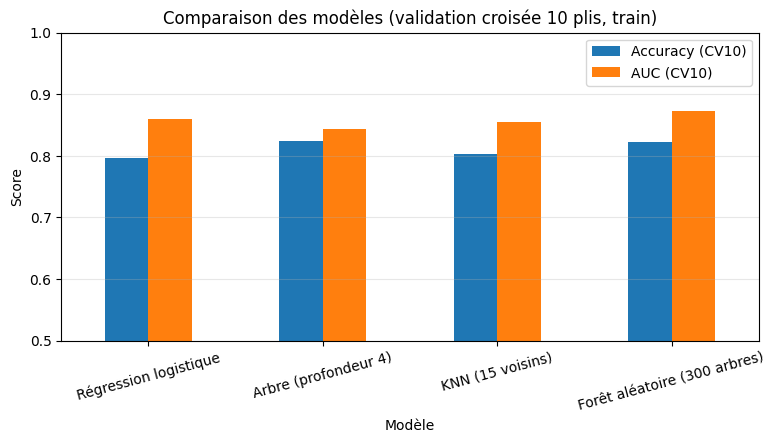

In [12]:
modeles = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Arbre (profondeur 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
    "KNN (15 voisins)": KNeighborsClassifier(n_neighbors=15),
    "Forêt aléatoire (300 arbres)": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

lignes = []
for nom, modele in modeles.items():
    pipe = Pipeline([("prepro", faire_prepro()), ("modele", modele)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])
    lignes.append({"Modèle": nom,
                   "Accuracy (CV10)": r["test_accuracy"].mean(),
                   "Écart-type acc.": r["test_accuracy"].std(),
                   "AUC (CV10)": r["test_roc_auc"].mean(),
                   "Écart-type AUC": r["test_roc_auc"].std()})

comparatif = pd.DataFrame(lignes).set_index("Modèle").round(4)
display(comparatif)
comparatif.to_csv("tableau_comparatif_modeles.csv")       # livrable : tableau comparatif (CSV)
print("Tableau enregistré : tableau_comparatif_modeles.csv")

comparatif[["Accuracy (CV10)", "AUC (CV10)"]].plot(kind="bar", figsize=(9, 4), rot=15, ylim=(0.5, 1.0))
plt.title("Comparaison des modèles (validation croisée 10 plis, train)")
plt.ylabel("Score"); plt.grid(axis="y", alpha=0.3); plt.show()

### Évaluation finale du modèle retenu (une seule fois, sur le test)
Une fois le modèle choisi, on l'évalue **une fois** sur le test. *(Ici on affiche les quatre pour information, mais le choix
doit s'appuyer sur la validation croisée ci-dessus.)*

In [13]:
finals = []
for nom, modele in modeles.items():
    pipe = Pipeline([("prepro", faire_prepro()), ("modele", modele)]).fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    finals.append({"Modèle": nom, "Accuracy (test)": accuracy_score(y_test, (p >= 0.5).astype(int)),
                   "AUC (test)": roc_auc_score(y_test, p)})
display(pd.DataFrame(finals).set_index("Modèle").round(4))

,Accuracy (test),AUC (test)
Modèle,,
Régression logistique,0.7713,0.8387
Arbre (profondeur 4),0.7892,0.8296
KNN (15 voisins),0.7892,0.8402
Forêt aléatoire (300 arbres),0.7803,0.8376


✍️ **Ma réponse C.1** — *tableau comparatif à joindre au rapport (livrable)* + choix argumenté :

| Modèle | Accuracy CV10 | AUC CV10 | Explicable ? |
|---|---|---|---|
| Régression logistique | | | **Oui** : coefficients et rapports de cotes |
| Arbre (profondeur 4) | | | **Oui** : règles SI… ALORS lisibles |
| KNN (15 voisins) | | | Faible : « il ressemble à ces voisins » |
| Forêt aléatoire | | | **Non** : 300 arbres = boîte noire |

**Modèle choisi : …**, car *(les scores sont proches / la forêt gagne de peu mais perd en explicabilité)*.
Dans un contexte où **chaque décision doit être justifiée** (médecine, banque), on privilégie un modèle **explicable** dont les
performances sont proches du meilleur : ici *(la régression logistique)*. Si seule la performance compte, la forêt peut être préférée.

---
# PARTIE D — Avec Orange · *3 points*
**But** : refaire la comparaison avec un outil visuel.

### Workflow Orange à construire
`File (titanic.csv)` → **Logistic Regression**, **Tree**, **kNN**, **Random Forest** → **Test and Score** → **ROC Analysis** ;
**Logistic Regression** → **Nomogram**

| Étape | Widget | Réglages et pourquoi |
|---|---|---|
| 1 | **File** | `Survived` en **target** (type **categorical**) ; `PassengerId`, `Name`, `Ticket`, `Cabin` en **skip** (identifiants/texte inutilisables tels quels) |
| 2 | **Logistic Regression**, **Tree** (profondeur 4), **kNN** (15 voisins), **Random Forest** → **Test and Score** | **Cross validation 10 plis** ; relever **CA** (accuracy) et **AUC**. Le kNN semble-t-il bon ? Ajouter un **Preprocess** (*Normalize features*) entre File et kNN et comparer |
| 3 | **ROC Analysis** | Superposer les quatre courbes |
| 4 | **Nomogram** (sur la régression logistique) | Quelle variable a la plus grande **échelle de points** ? |

👉 Enregistrer en **`.ows`** : c'est un livrable.

### Vérification en Python
**a) Effet de la normalisation sur le KNN** (l'âge va de 0 à 80 et le prix du billet de 0 à 500 : sans mise à l'échelle,
le billet écrase les distances, comme la masse dans le TP K-means).

In [14]:
res = []
for std in (False, True):
    pipe = Pipeline([("prepro", faire_prepro(standardiser=std)), ("modele", KNeighborsClassifier(n_neighbors=15))])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])
    res.append({"KNN 15 voisins": "avec normalisation" if std else "sans normalisation",
                "Accuracy": r["test_accuracy"].mean().round(4), "AUC": r["test_roc_auc"].mean().round(4)})
display(pd.DataFrame(res).set_index("KNN 15 voisins"))

,Accuracy,AUC
KNN 15 voisins,,
sans normalisation,0.7457,0.7940
avec normalisation,0.8024,0.8542


**b) Équivalent du Nomogram** : l'« échelle de points » d'une variable correspond à l'**étendue de son effet sur le score**
(coefficient × étendue de la variable). Calcul à partir du modèle non standardisé de B.3 :

,étendue de l'effet sur le score (log-cote)
Age,3.30
femme,2.79
Pclass,2.44
famille,1.61


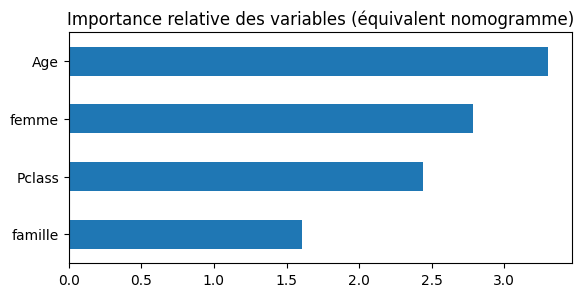

In [15]:
coef = dict(zip(Xb_train.columns, lr_brut.coef_[0]))
etendue = {
    "femme": abs(coef["femme"]) * 1,
    "Age": abs(coef["Age"]) * (X_train["Age"].max() - X_train["Age"].min()),
    "famille": abs(coef["famille"]) * (X_train["famille"].max() - X_train["famille"].min()),
    "Pclass": max(0, coef["classe_2"], coef["classe_3"]) - min(0, coef["classe_2"], coef["classe_3"]),
}
echelle = pd.Series(etendue).sort_values(ascending=False)
display(echelle.round(2).to_frame("étendue de l'effet sur le score (log-cote)"))
echelle.plot(kind="barh", color="tab:blue", figsize=(6.5, 3)).invert_yaxis()
plt.title("Importance relative des variables (équivalent nomogramme)"); plt.show()

✍️ **Ma réponse D** *(valeurs lues dans Orange)* :

| Modèle | CA | AUC |
|---|---|---|
| Logistic Regression | | |
| Tree (prof. 4) | | |
| kNN (15) — sans Preprocess | | |
| kNN (15) — avec Normalize | | |
| Random Forest | | |

* Le kNN est-il bon ? *(…)* Que change la normalisation ? *(…)*
* ROC Analysis : le modèle dont la courbe domine est *(…)*.
* Nomogram : la variable avec la plus grande échelle de points est *(…)* (attendu : le sexe).
* Orange et Python donnent-ils le même classement des modèles ? *(…)*

---
#  Conclusion générale (bilan du module)
* **Régression logistique** : un score linéaire transformé en probabilité par la **sigmoïde** ; chaque coefficient se lit en **rapport de cotes**.
* **Seuil et ROC** : la décision dépend du seuil (compromis rappel/précision) ; la **courbe ROC / AUC** juge le modèle indépendamment du seuil.
* **Comparer les modèles** : mêmes données, même préparation, même validation croisée ; on ne choisit jamais d'après le test.
* **Choix final** : la meilleure performance n'est pas le seul critère : l'**explicabilité** compte quand il faut justifier chaque décision.
* **Fil rouge du module** : séparer train/test, mettre à l'échelle quand les distances comptent (K-means, KNN), évaluer honnêtement.

